In [16]:

import pandas as pd
import matplotlib.pyplot as plt
import platform

# 그래프 한글 설정
fonts = {
    "Windows": "Malgun Gothic",
    "Darwin": "AppleGothic"
}
name = fonts.get(platform.system(), "NanumGothic")

plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

# CSV 파일 읽기
df = pd.read_csv("sales_data.csv")

# 날짜 컬럼 변환
dates = ["order_date", "shipping_date", "delivery_date"]

for col in dates:
    df[col] = pd.to_datetime(df[col])

# 데이터 크기 확인
print(df.shape)


(1030, 14)


In [17]:

# 중복 제거 전 데이터 개수
before = len(df)

# 완전히 중복된 행 제거
df = df.drop_duplicates()

# 제거 전후 출력
print(before, "->", len(df))


1030 -> 1004


In [18]:

# 수량이 100을 초과하는 행 찾기
bad = df["quantity"] > 100

# 총매출 / 단가로 원래 수량 복원
df.loc[bad, "quantity"] = (
    df.loc[bad, "total_sales"] /
    df.loc[bad, "unit_price"]
).round().astype(int)

# 총매출과 수량 × 단가의 차이 계산
diff = (
    df["total_sales"] -
    df["quantity"] * df["unit_price"]
).abs()

print(
    "고친 줄 :", bad.sum(),
    " 수량 최대 :", df["quantity"].max(),
    " 총액 안 맞는 줄 :", (diff > 1).sum()
)


고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [19]:

# 도착일이 배송일보다 빠른 데이터 표시
df["date_error"] = (
    df["delivery_date"] < df["shipping_date"]
)

# 날짜 오류 개수 출력
print("날짜 오류 :", df["date_error"].sum())

# 전처리 결과 저장
df.to_csv("sales_clean.csv", index=False)

# 최종 데이터 크기 출력
print(df.shape)


날짜 오류 : 147
(1004, 15)


## ⑤ Q1. 배송 기간은 보통 며칠인가

평균 배송 기간 : 22.05 일
중앙값 배송 기간 : 2.0 일


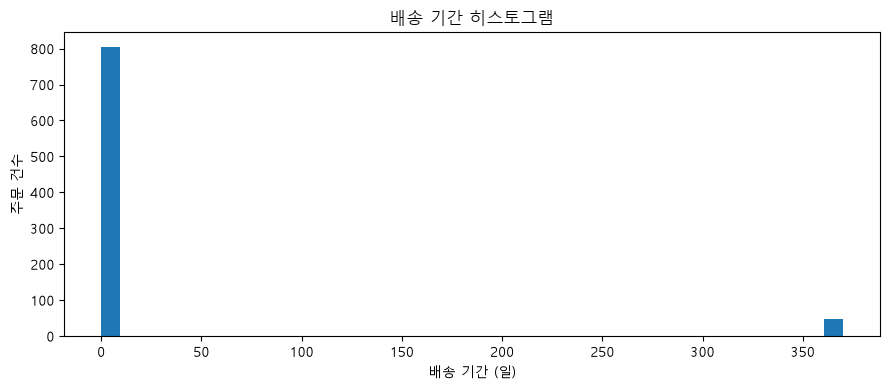

300일 초과 건수 : 47


,order_date,shipping_date,delivery_date,status,days
11,2023-01-12,2023-01-15,2024-01-15,배송완료,365
20,2023-01-21,2023-01-23,2024-01-27,배송완료,369
29,2023-01-30,2023-02-03,2024-02-03,배송완료,365
41,2023-02-11,2023-02-14,2024-02-17,배송완료,368
68,2023-03-10,2023-03-14,2024-03-12,배송완료,364
99,2023-04-10,2023-04-11,2024-04-12,배송완료,367
110,2023-04-21,2023-04-25,2024-04-24,배송완료,365
131,2023-05-12,2023-05-13,2024-05-16,배송완료,369
165,2023-06-15,2023-06-16,2024-06-18,배송완료,368
192,2023-07-12,2023-07-13,2024-07-14,배송중,367


300일 이하 평균 : 1.93 일
300일 이하 중앙값 : 2.0 일


In [20]:

# 날짜 오류가 없고 도착일이 존재하는 데이터만 선택
valid = df.loc[
    (~df["date_error"]) &
    (df["delivery_date"].notna())
].copy()

# 배송 기간 계산 (일 단위)
valid["days"] = (
    valid["delivery_date"] -
    valid["shipping_date"]
).dt.days

days = valid["days"]

# 평균과 중앙값
print("평균 배송 기간 :", round(days.mean(), 2), "일")
print("중앙값 배송 기간 :", days.median(), "일")

# 배송 기간 히스토그램
plt.figure(figsize=(9, 4))
plt.hist(days, bins=40)

plt.title("배송 기간 히스토그램")
plt.xlabel("배송 기간 (일)")
plt.ylabel("주문 건수")

plt.tight_layout()
plt.show()

# 300일 초과 데이터 확인
long_days = valid.loc[
    valid["days"] > 300,
    ["order_date", "shipping_date", "delivery_date",
     "status", "days"]
]

print("300일 초과 건수 :", len(long_days))
display(long_days)

# 300일 초과를 제외한 결과도 비교
normal_days = days[days <= 300]

print("300일 이하 평균 :", round(normal_days.mean(), 2), "일")
print("300일 이하 중앙값 :", normal_days.median(), "일")


배송 기간의 전체 평균은 22.05일, 중앙값은 2일로 큰 차이가 나타났으며, 이는 364~370일에 몰려 있는 장기 배송 기록 47건이 평균을 높였기 때문이다.

해당 기록은 날짜 입력 오류 가능성이 있으나 정확한 원인을 확인할 수 없어 원본에는 유지하고 일반적인 배송 기간 분석에서만 제외하였다. 제외 후 평균은 1.93일, 중앙값은 2일로 나타났다.

## ⑥ Q2. 만족도가 낮을수록 반품이 많은가?

만족도별 반품 비율 (%)
satisfaction
1.0     7.59
2.0    11.96
3.0     7.81
4.0     8.72
5.0     6.93
Name: is_return, dtype: float64


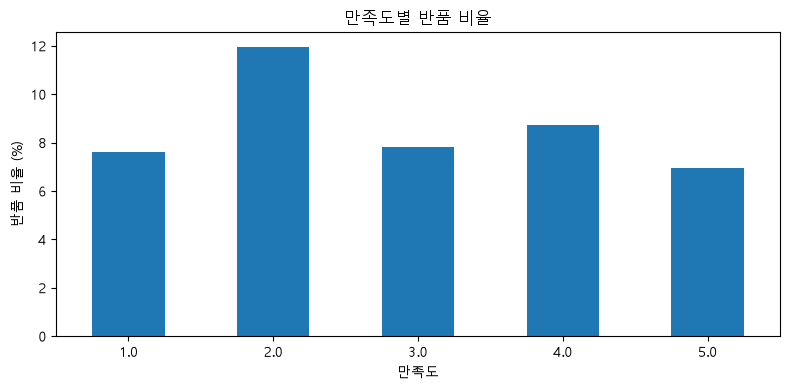

In [21]:

# 만족도가 비어 있는 행 제외
q2 = df.dropna(subset=["satisfaction"]).copy()

# 반품 여부
q2["is_return"] = q2["status"] == "반품"

# 만족도별 반품률 계산
return_rate = (
    q2.groupby("satisfaction")["is_return"]
    .mean() * 100
)

# 결과 출력
print("만족도별 반품 비율 (%)")
print(return_rate.round(2))

# 막대그래프
plt.figure(figsize=(8, 4))

return_rate.plot.bar()

plt.title("만족도별 반품 비율")
plt.xlabel("만족도")
plt.ylabel("반품 비율 (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


만족도별 반품률을 비교한 결과, 만족도가 낮을수록 반품률이 높아지는 일정한 경향은 나타나지 않았다.

만족도 2점의 반품률이 11.96%로 가장 높고, 5점은 6.93%로 가장 낮았지만, 1점은 7.59%, 4점은 8.72%로 만족도에 따라 반품률이 일정하게 변하지 않았다.

## ⑦ Q3. 카테고리 매출 1위의 이유는 무엇인가?

In [22]:

# 카테고리별 집계
result = df.groupby("category").agg(
    order_count=("category", "size"),
    total_sales=("total_sales", "sum"),
    avg_price=("unit_price", "mean"),
    avg_quantity=("quantity", "mean")
)

# 매출을 억 원 단위로 변환한 컬럼 추가
result["sales_100m"] = result["total_sales"] / 1e8

# 매출 높은 순서로 정렬
result = result.sort_values(
    "total_sales", ascending=False
)

# 필요한 네 개 항목 출력
display(
    result[
        ["order_count", "sales_100m",
         "avg_price", "avg_quantity"]
    ].round(2)
)

# 매출 1위 카테고리 확인
print("매출 1위 :", result.index[0])


,order_count,sales_100m,avg_price,avg_quantity
category,,,,
가구,213,28.43,257322.91,51.04
식품,210,25.13,255232.93,47.31
전자제품,207,24.72,249651.61,47.96
도서,204,24.53,238500.64,49.50
의류,170,21.82,249447.16,51.61


매출 1위 : 가구


총매출 1위는 가구로 28.43억 원이며, 주문 건수 213건과 평균 단가 257,322.91원으로 두 항목 모두 가장 높았다.

가구의 평균 수량도 51.04개로 높은 편이며, 매출 2위인 식품(47.31개)보다 많아 주문 건수, 단가, 수량이 복합적으로 높은 매출에 기여한 것으로 해석할 수 있다.